In [1]:
# --- Install required libraries ---
!pip install torch torchvision matplotlib medmnist pytorch-fid --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.2 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 30.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 79.8 MB/s eta 0:00:00:00:0100:01


In [2]:
import os
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader, ConcatDataset
import torch.nn.functional as Fnn

import torchvision.models as models
import torchvision.transforms as transforms
import torchvision.transforms.functional as F
from torchvision.utils import save_image, make_grid

import matplotlib.pyplot as plt
from tqdm import tqdm

import medmnist
from medmnist import INFO, Evaluator

from pytorch_fid import fid_score


In [3]:
print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [4]:
data_flag = 'bloodmnist'
download = True
BATCH_SIZE = 128

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

DataClass = getattr(medmnist, info['python_class'])

In [5]:

# preprocessing
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # [-1, 1]
])


# Load all splits
train = DataClass(split='train', transform=data_transform, download=True)
val = DataClass(split='val', transform=data_transform, download=True)
test = DataClass(split='test', transform=data_transform, download=True)

# Combine them into a single dataset
full_dataset = ConcatDataset([train, val, test])
dataloader = DataLoader(full_dataset, batch_size=128, shuffle=True)

100%|██████████| 35.5M/35.5M [00:02<00:00, 13.1MB/s]


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [7]:
# Updated Generator with deeper architecture and spectral norm
class Generator(nn.Module):
    def __init__(self, latent_dim=128, img_channels=3, feature_g=128):
        super().__init__()
        self.net = nn.Sequential(
            # Input: latent_dim x 1 x 1
            nn.ConvTranspose2d(latent_dim, feature_g * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_g * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_g * 8, feature_g * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_g * 4, feature_g * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g * 2),
            nn.ReLU(True),
            nn.Dropout(0.3),  # added dropout

            nn.ConvTranspose2d(feature_g * 2, feature_g, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g),
            nn.ReLU(True),
            nn.Dropout(0.3),  # added dropout

            nn.Conv2d(feature_g, img_channels, 3, 1, 1, bias=False),
            nn.Tanh()
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.normal_(m.weight, 0.0, 0.02)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.normal_(m.weight, 1.0, 0.02)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = x.view(x.size(0), x.size(1), 1, 1)  # reshape noise vector
        out = self.net(x)
        return out[:, :, 2:30, 2:30]  # crop to 28x28

In [8]:
import torch.nn as nn

def spectral_norm(module, mode=True):
    if mode:
        return nn.utils.spectral_norm(module)
    return module

class Discriminator(nn.Module):
    def __init__(self, img_channels=3, feature_d=64, dropout_prob=0.3):
        super().__init__()
        self.net = nn.Sequential(
            spectral_norm(nn.Conv2d(img_channels, feature_d, 4, 2, 1, bias=False)),  # 28 -> 14
            nn.LeakyReLU(0.25, inplace=True),
            nn.Dropout2d(dropout_prob),

            spectral_norm(nn.Conv2d(feature_d, feature_d * 2, 4, 2, 1, bias=False)),  # 14 -> 7
            nn.LeakyReLU(0.25, inplace=True),
            nn.Dropout2d(dropout_prob),

            spectral_norm(nn.Conv2d(feature_d * 2, feature_d * 4, 4, 2, 1, bias=False)),  # 7 -> 3
            nn.LeakyReLU(0.25, inplace=True),
            nn.Dropout2d(dropout_prob),

            spectral_norm(nn.Conv2d(feature_d * 4, feature_d * 8, 3, 1, 0, bias=False)),  # 3 -> 1
            nn.LeakyReLU(0.25, inplace=True),
            nn.Dropout2d(dropout_prob),

            spectral_norm(nn.Conv2d(feature_d * 8, 1, 1, 1, 0, bias=False))  # 1 -> 1
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, x):
        return self.net(x).view(-1)



In [ ]:
criterion = nn.MSELoss()

In [10]:
# Label smoothing and noisy labels helper
def smooth_labels(labels, offset=0.1):
    return labels * (1 - offset) + (offset / 2)

In [11]:
# Initialize models with improved feature sizes
latent_dim = 128
G = Generator(latent_dim=latent_dim).to(device)
D = Discriminator().to(device)

In [12]:
# Optimizers with learning rate schedulers
lr_G = 2e-4
lr_D = 2e-4
optimizerG = optim.Adam(G.parameters(), lr=lr_G, betas=(0.5, 0.999))
optimizerD = optim.Adam(D.parameters(), lr=lr_D, betas=(0.5, 0.999))

schedulerG = optim.lr_scheduler.StepLR(optimizerG, step_size=10, gamma=0.5)
schedulerD = optim.lr_scheduler.StepLR(optimizerD, step_size=10, gamma=0.5)

real_label_val = 0.9
fake_label_val = 0.1

num_epochs = 100

In [13]:
print("Starting improved DCGAN training...")

G_losses = []
D_losses = []

for epoch in range(num_epochs):
    G.train()
    D.train()
    running_G_loss = 0.0
    running_D_loss = 0.0

    loop = tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for real_images, _ in loop:
        batch_size = real_images.size(0)
        real_images = real_images.to(device)

        for _ in range(1):
            D.zero_grad()

            # Real images with label smoothing and noise
            labels_real = torch.full((batch_size,), real_label_val, device=device)
            labels_real = smooth_labels(labels_real, offset=0.1)
            labels_real += 0.05 * torch.rand_like(labels_real)  # add noise
            output_real = D(real_images)
            lossD_real = criterion(output_real, labels_real)

            # Fake images
            noise = torch.randn(batch_size, latent_dim, device=device)
            fake_images = G(noise).detach()  # detach to avoid gradient in G here
            labels_fake = torch.full((batch_size,), fake_label_val, device=device)
            labels_fake = smooth_labels(labels_fake, offset=0.1)
            labels_fake -= 0.05 * torch.rand_like(labels_fake)  # add noise
            output_fake = D(fake_images)
            lossD_fake = criterion(output_fake, labels_fake)

            lossD = lossD_real + lossD_fake
            lossD.backward()
            optimizerD.step()

            running_D_loss += lossD.item() / 2
        # Train Generator once
        G.zero_grad()
        labels_gen = torch.full((batch_size,), real_label_val, device=device)
        noise = torch.randn(batch_size, latent_dim, device=device)
        fake_images = G(noise)
        output_gen = D(fake_images)
        lossG = criterion(output_gen, labels_gen)
        lossG.backward()
        optimizerG.step()

        running_G_loss += lossG.item()

        loop.set_postfix(D_loss=running_D_loss/(loop.n+1), G_loss=running_G_loss/(loop.n+1))

    schedulerG.step()
    schedulerD.step()

    G_losses.append(running_G_loss / len(dataloader))
    D_losses.append(running_D_loss / len(dataloader))

    print(f"Epoch [{epoch+1}/{num_epochs}] D_loss: {D_losses[-1]:.4f}, G_loss: {G_losses[-1]:.4f}")


Starting improved DCGAN training...


Epoch 1/100: 100%|██████████| 134/134 [00:22<00:00,  6.07it/s, D_loss=0.162, G_loss=0.518]


Epoch [1/100] D_loss: 0.1622, G_loss: 0.5183


Epoch 2/100: 100%|██████████| 134/134 [00:21<00:00,  6.30it/s, D_loss=0.163, G_loss=0.292]


Epoch [2/100] D_loss: 0.1629, G_loss: 0.2920


...

Epoch [98/100] D_loss: 0.1411, G_loss: 0.1895


Epoch 99/100: 100%|██████████| 134/134 [00:21<00:00,  6.33it/s, D_loss=0.141, G_loss=0.19] 


Epoch [99/100] D_loss: 0.1410, G_loss: 0.1897


Epoch 100/100: 100%|██████████| 134/134 [00:21<00:00,  6.31it/s, D_loss=0.14, G_loss=0.19] 

Epoch [100/100] D_loss: 0.1403, G_loss: 0.1896


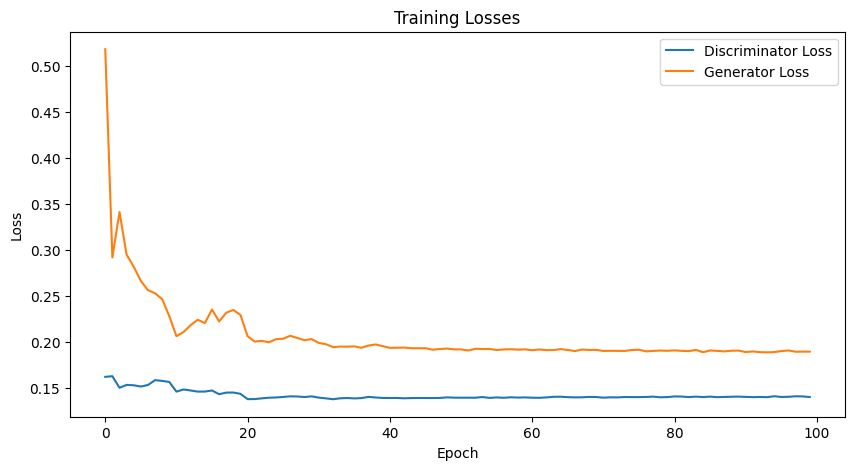

In [14]:
# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(D_losses, label='Discriminator Loss')
plt.plot(G_losses, label='Generator Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Losses')
plt.legend()
plt.savefig('training_losses.png')
plt.show()

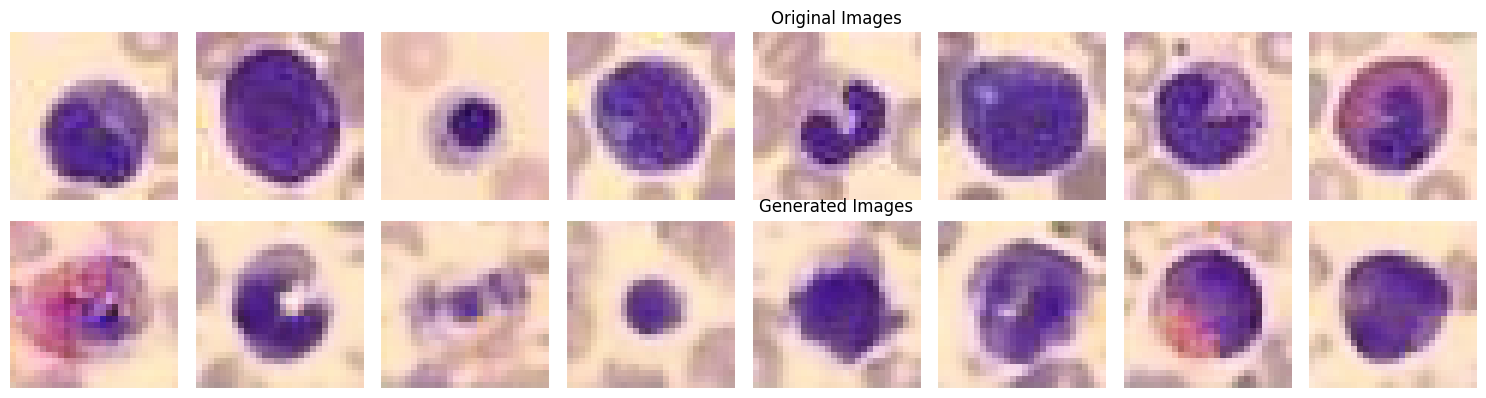

In [15]:
# Generate comparison samples
num_samples = 8
real_samples = next(iter(dataloader))[0][:num_samples].to(device)
noise = torch.randn(num_samples, latent_dim, device=device)

G.eval()
with torch.no_grad():
    fake_samples = G(noise)

# Convert from [-1,1] to [0,1] for display
real_samples = (real_samples + 1) / 2
fake_samples = (fake_samples + 1) / 2

# Plot comparison
fig, axes = plt.subplots(2, num_samples, figsize=(15, 4))
for i in range(num_samples):
    # Original images (top row)
    axes[0, i].imshow(real_samples[i].cpu().permute(1, 2, 0))
    axes[0, i].axis('off')
    if i == num_samples//2:
        axes[0, i].set_title('Original Images')

    # Generated images (bottom row)
    axes[1, i].imshow(fake_samples[i].cpu().permute(1, 2, 0))
    axes[1, i].axis('off')
    if i == num_samples//2:
        axes[1, i].set_title('Generated Images')

plt.tight_layout()
plt.savefig('comparison.png')
plt.show()


In [16]:
import os
from torchvision.utils import save_image
from tqdm import tqdm

real_dir = '/tmp/real_samples_dcgan'
gen_dir = '/tmp/generated_samples_dcgan'

os.makedirs(real_dir, exist_ok=True)
os.makedirs(gen_dir, exist_ok=True)

print("Saving 10,000 real images...")
for i in tqdm(range(10000)):
    img, _ = full_dataset[i]
    save_image(img, os.path.join(real_dir, f"real_{i}.png"))

print("Saving 10,000 generated images...")
batch_size = 128
latent_dim = 128
num_batches = 10000 // batch_size

G.eval()
with torch.no_grad():
    for i in tqdm(range(num_batches)):
        noise = torch.randn(batch_size, latent_dim, device=device)
        gen_imgs = G(noise).clamp(-1, 1)
        gen_imgs = (gen_imgs + 1) / 2
        for j in range(batch_size):
            idx = i * batch_size + j
            if idx >= 10000:
                break
            save_image(gen_imgs[j], os.path.join(gen_dir, f"gen_{idx}.png"))

print("Calculating FID...")
fid_value = fid_score.calculate_fid_given_paths([real_dir, gen_dir], batch_size=50, device=device, dims=2048)
print(f"FID score: {fid_value:.4f}")

Saving 10,000 real images...


100%|██████████| 10000/10000 [00:07<00:00, 1331.59it/s]


Saving 10,000 generated images...


100%|██████████| 78/78 [00:08<00:00,  9.70it/s]


Calculating FID...


Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 359MB/s]
100%|██████████| 200/200 [00:21<00:00,  9.43it/s]


FID score: 96.8763
